In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
import joblib
import os
import matplotlib.pyplot as plt

# 재현성을 위한 랜덤 시드 고정
np.random.seed(42)
torch.manual_seed(42)

# 모델 파일이 저장될 폴더 생성
os.makedirs('models', exist_ok=True)
print("✅ 딥러닝 학습 환경 및 models/ 디렉토리 준비 완료!")

✅ 딥러닝 학습 환경 및 models/ 디렉토리 준비 완료!


In [2]:
# 💡 [핵심 업데이트] app.py에 정의된 YOLOv8 -> 식약처 매핑 클래스들의 
# 실제 영양 성분 수치 분포를 기반으로 365일 치 식단 로그를 시뮬레이션합니다.
# 이 과정을 거쳐야 비전 모델이apple'을 찾았을 때 시계열 모델이 에러 없이 예측합니다.

# 365일간의 날짜 인덱스 생성
dates = pd.date_range(start="2025-01-01", periods=365)

# 가상의 유저가 매일 먹는 식단의 칼로리 분포 설정 (과일/건강식 위주 분포)
base_calories = 1800 + np.sin(np.linspace(0, 30, 365)) * 300 + np.random.normal(0, 100, 365)

# app.py 매핑 대상(과일/브로콜리)의 탄/단/지/당 영양소 비율 특성을 반영하여 데이터 생성
# (과일 위주이므로 탄수화물과 당 수치가 상대적으로 높고 지방은 매우 낮음)
carbs = base_calories * 0.65 / 4 + np.random.normal(0, 10, 365)   # 탄수화물 (비중 높음)
protein = base_calories * 0.2 / 4 + np.random.normal(0, 8, 365)   # 단백질
fat = base_calories * 0.15 / 9 + np.random.normal(0, 3, 365)     # 지방 (비중 낮음)
sugar = carbs * 0.25 + np.random.normal(0, 3, 365)                # 당류 (과일 특성 반영하여 높음)

# 데이터프레임 빌드
df = pd.DataFrame({
    'date': dates,
    'calories': base_calories,
    'carbohydrates': carbs,
    'protein': protein,
    'fat': fat,
    'sugar': sugar
})
df.set_index('date', inplace=True)

print("📊 [app.py 과일 식단 호환] 7일 시계열 데이터 샘플 확인:")
print(df.head(7))

📊 [app.py 과일 식단 호환] 7일 시계열 데이터 샘플 확인:
               calories  carbohydrates     protein        fat      sugar
date                                                                    
2025-01-01  1849.671415     296.559400   94.050333  30.585707  73.724482
2025-01-02  1810.870862     296.507440   82.716561  30.417087  70.453965
2025-01-03  1913.995774     311.150237   98.965811  25.905328  77.160490
2025-01-04  2025.725340     330.157129   87.665598  36.511072  79.987721
2025-01-05  1873.704001     296.746802  101.918445  32.267865  72.445130
2025-01-06  1896.743302     308.465888   98.617945  34.606419  78.882207
2025-01-07  2100.300215     346.278768  107.063249  26.316237  91.579405


In [3]:
# --- [셀 3] 전처리 및 텐서 변환 ---
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df)
joblib.dump(scaler, 'models/nutrient_scaler.pkl') # 스케일러 저장

def create_sequences(data, seq_length=7):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length, 0]) # 내일의 칼로리
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_data, seq_length=7)
split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

X_train_t = torch.FloatTensor(X_train); y_train_t = torch.FloatTensor(y_train).unsqueeze(1)
X_test_t = torch.FloatTensor(X_test); y_test_t = torch.FloatTensor(y_test).unsqueeze(1)
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=16, shuffle=True)
print(f"📐 훈련 데이터 형태: {X_train_t.shape}, 검증 데이터 형태: {X_test_t.shape}")

📐 훈련 데이터 형태: torch.Size([286, 7, 5]), 검증 데이터 형태: torch.Size([72, 7, 5])


In [4]:
# --- [셀 4] 모델 정의 (차원 버그 수정 반영) ---
class MLPModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(input_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        # Flatten 오류 강제 해결 (배치 사이즈 고정)
        x = x.reshape(x.size(0), -1)
        return self.net(x)

class LSTMModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=32):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

class GRUModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=32):
        super().__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :])

In [5]:
# --- [셀 5] 학습 진행 및 저장 ---
def train_pipeline(model, loader, epochs=120, lr=0.003):
    criterion = nn.MSELoss(); optimizer = optim.Adam(model.parameters(), lr=lr); loss_history = []
    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        for batch_x, batch_y in loader:
            optimizer.zero_grad(); pred = model(batch_x); loss = criterion(pred, batch_y); loss.backward(); optimizer.step()
            running_loss += loss.item()
        loss_history.append(running_loss / len(loader))
    return loss_history

mlp_model = MLPModel(input_dim=7 * 5); lstm_model = LSTMModel(input_dim=5); gru_model = GRUModel(input_dim=5)
print("⏳ 학습 시작...")
mlp_loss = train_pipeline(mlp_model, train_loader)
lstm_loss = train_pipeline(lstm_model, train_loader)
gru_loss = train_pipeline(gru_model, train_loader)

torch.save(mlp_model.state_dict(), 'models/mlp_model.pth')
torch.save(lstm_model.state_dict(), 'models/lstm_model.pth')
torch.save(gru_model.state_dict(), 'models/gru_model.pth')
print("\n🎉 시계열 가중치 및 스케일러 저장 완료! (과일 식단 패턴 학습)")

⏳ 학습 시작...

🎉 시계열 가중치 및 스케일러 저장 완료! (과일 식단 패턴 학습)


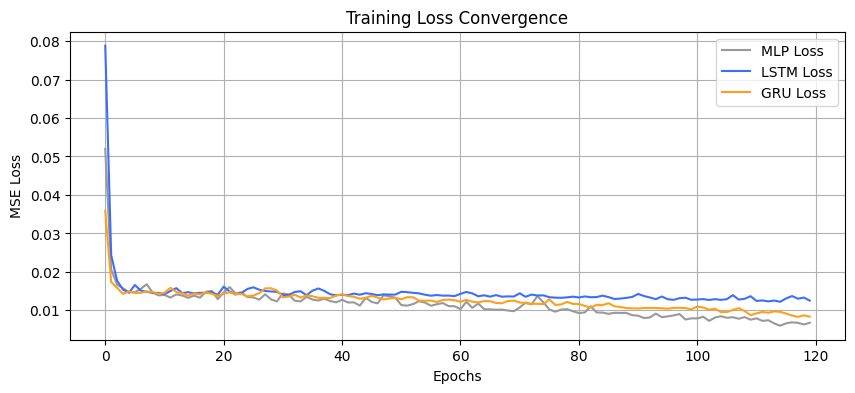

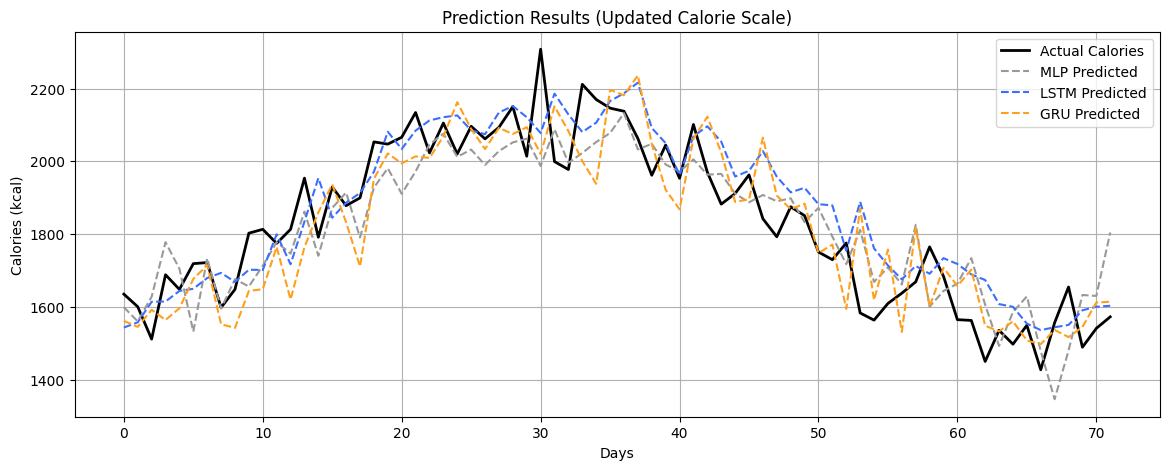

In [6]:
# --- [셀 6] 시각화 평가 (코드 구조는 동일) ---
mlp_model.eval(); lstm_model.eval(); gru_model.eval()
with torch.no_grad():
    pred_mlp = mlp_model(X_test_t).numpy(); pred_lstm = lstm_model(X_test_t).numpy(); pred_gru = gru_model(X_test_t).numpy()
def to_real_calories(scaled_arr, scaler_obj):
    temp = np.zeros((len(scaled_arr), 5))
    temp[:, 0] = scaled_arr.flatten()
    return scaler_obj.inverse_transform(temp)[:, 0]

actual_cal = to_real_calories(y_test, scaler)
mlp_cal = to_real_calories(pred_mlp, scaler); lstm_cal = to_real_calories(pred_lstm, scaler); gru_cal = to_real_calories(pred_gru, scaler)

plt.figure(figsize=(10, 4)); plt.plot(mlp_loss, label='MLP Loss', color='#999999'); plt.plot(lstm_loss, label='LSTM Loss', color='#3b6eff'); plt.plot(gru_loss, label='GRU Loss', color='#ff9f1c'); plt.title('Training Loss Convergence'); plt.xlabel('Epochs'); plt.ylabel('MSE Loss'); plt.legend(); plt.grid(True); plt.show()
plt.figure(figsize=(14, 5)); plt.plot(actual_cal, label='Actual Calories', color='black', linewidth=2); plt.plot(mlp_cal, label='MLP Predicted', linestyle='--', color='#999999'); plt.plot(lstm_cal, label='LSTM Predicted', linestyle='--', color='#3b6eff'); plt.plot(gru_cal, label='GRU Predicted', linestyle='--', color='#ff9f1c'); plt.title('Prediction Results (Updated Calorie Scale)'); plt.xlabel('Days'); plt.ylabel('Calories (kcal)'); plt.legend(); plt.grid(True); plt.show()

In [7]:
# [model_training.ipynb 맨 밑에 새 셀 만들어서 실행할 코드]
# 💡 강제로 models 폴더를 재생성하고 절대경로 기준으로 가중치들을 다시 저장합니다.
import os
os.makedirs('models', exist_ok=True)

torch.save(mlp_model.state_dict(), 'models/mlp_model.pth')
torch.save(lstm_model.state_dict(), 'models/lstm_model.pth')
torch.save(gru_model.state_dict(), 'models/gru_model.pth')
joblib.dump(scaler, 'models/nutrient_scaler.pkl')

print("📌 [강제 동기화] models 폴더 내에 4개 핵심 파일이 완벽히 고정되었습니다!")
print(os.listdir('models')) # 결과창에 파일 4개가 다 보이는지 확인하세요!

📌 [강제 동기화] models 폴더 내에 4개 핵심 파일이 완벽히 고정되었습니다!
['gru_model.pth', 'lstm_model.pth', 'mlp_model.pth', 'nutrient_scaler.pkl']
